# Lesson 12. Giving a soft sphere axes of its own

[Course plan](../../README.md)

The point from the last lesson has no width. From any camera position it gives one address. Now we can surround it with a soft cloud. Joining places of equal weight around a round cloud gives a sphere. Stretching it in one direction and turning the whole cloud carries that same weight onto the surface of an ellipsoid.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. Three sizes for one cloud

Both views show a single wire surface. On the right we look along $z$, on the left from an angle. These are drawings without perspective for now. Three colored segments reach the surface along its own axes. The orange segment starts at 2 m, green at 0.75 m and purple at 1 m. Changing the angle moves their tips while preserving their lengths.

Three equal scales give a sphere. A turn through any angle moves the colored segments but leaves the geometric outline unchanged. With one axis longer, only some turns preserve the silhouette. The table beneath the drawing ties that observation to the shape's numbers.

In [2]:
display(demos.geometry_lab(12, "en"))

## 2. Computing a weight and drawing a shell

For now the axes line up with the world's. The center is $\mu=(0,0,0)$ m and scales are $s_x=2$, $s_y=0.75$, $s_z=1$ m. Along each axis we subtract the center and divide by **that axis's** scale. At $(2,0,0)$ we get $(2/2,0/0.75,0/1)=(1,0,0)$ with no units left. At $(0,0.75,0)$ we get $(0,1,0)$. The squares sum to 1 in both cases. Thus the weight from lesson 3 agrees even though the distances in meters differ:

$$
D^2=h_x^2+h_y^2+h_z^2,\qquad G=\exp(-D^2/2)=\exp(-1/2)\approx0.607.
$$

Here $h$ holds three relative displacements. $D^2$ measures squared distance on the cloud's own scales, and $G$ is a relative weight peaking at 1 in the center. The wire drawing connects only places where $D^2=1$. Weight keeps falling beyond the wire. The cloud has no hard boundary there.

To draw the surface we can reverse the calculation. The unit sphere contains $h=(0.6,0.8,0)$ because $0.6^2+0.8^2=1$. Scaling along local axes gives $(1.2,0.6,0)$ m. Rotation $R$ comes next, followed by the addition of the center. The short expression $P=\mu+RSh$ uses the diagonal matrix $S$. Its diagonal holds the three scales and every other entry is zero. Multiplying by it gives exactly $(s_x h_x,s_y h_y,s_z h_z)$.

In [3]:
scales = np.array([2., .75, 1.])
h = np.array([.6, .8, 0.])
print("Sh =", scales*h, "m; G =", np.exp(-(h @ h)/2))
assert np.isclose(h @ h, 1)

Sh = [1.2 0.6 0. ] m; G = 0.6065306597126334


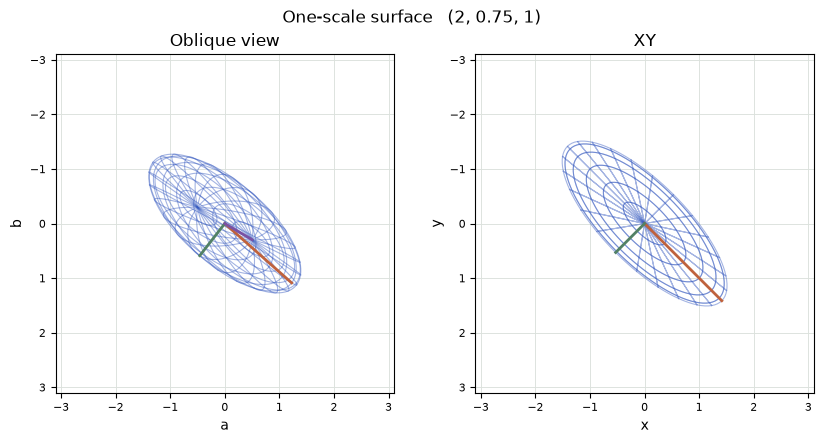

In [4]:
fig = demos.ellipsoid_figure("en")
plt.show()

## 3. An axis, an angle and four rotation numbers

A rotation axis is an arrow that stays put during the turn. A $90^\circ$ turn about $z$ takes right $(1,0,0)$ to down $(0,1,0)$. The three columns of $R$ are the new locations of the old axes. For this turn they are $(0,1,0)$, $(-1,0,0)$ and $(0,0,1)$. That already suffices to apply $R$ to any point.

A **quaternion** stores a rotation in four numbers, handy when fitting the rotation during learning. Our order is $q=(w,x,y,z)$ with the scalar first. These $x,y,z$ belong to the rotation record and do not locate the center. If the axis is given by arrow $a=(0,0,2)$, we first divide by its length $\sqrt{0^2+0^2+2^2}=2$. That gives unit axis $n=(0,0,1)$. A zero arrow has no direction. Axis and angle $\theta$ give

$$
w=\cos(\theta/2),\qquad (x,y,z)=n\sin(\theta/2).
$$

For $\theta=90^\circ$ the half angle is $45^\circ$. Both cosine and sine are $\sqrt{2}/2\approx0.7071$. This gives $q=(0.7071,0,0,0.7071)$. Its four squared entries add up to 1. If learning supplies $(2,0,0,2)$, we first divide every component by the length $\sqrt{2^2+2^2}=\sqrt{8}$. That recovers the same unit quaternion. For $(0,0,0,0)$ the division is undefined.

Why half the angle? For a turn about $z$, the rightward unit arrow becomes $(w^2-z^2,\,2wz,\,0)$. Writing $w=\cos t$ and $z=\sin t$ turns this into $(\cos(2t),\sin(2t),0)$ by the double-angle identities. It has already turned through $2t$. A turn through $\theta$ therefore needs $t=\theta/2$ inside the representation. Our example gives $(0.5-0.5,\;2\cdot0.7071^2,\;0)\approx(0,1,0)$, just as in the drawing.

In [5]:
q = geo.axis_angle_quaternion([0,0,2], 90)
R = geo.quaternion_matrix(q)
print("q =", q, "\nR =\n", R, "\nR (1,0,0) =", R @ [1,0,0])
np.testing.assert_allclose(R, geo.quaternion_matrix([2,0,0,2]), atol=1e-14)

q = [0.7071 0.     0.     0.7071] 
R =
 [[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]] 
R (1,0,0) = [0. 1. 0.]


## 4. From quaternion to shape matrix

For any unit quaternion the same rules give the three turned axes. The first row below contains their horizontal components. To find the horizontal coordinate of a rotated point, each entry in the row multiplies the matching point coordinate and the three products are added.

$$
R=\begin{bmatrix}
1-2(y^2+z^2)&2(xy-zw)&2(xz+yw)\\
2(xy+zw)&1-2(x^2+z^2)&2(yz-xw)\\
2(xz-yw)&2(yz+xw)&1-2(x^2+y^2)
\end{bmatrix}.
$$

Here $xy$ means $x\cdot y$. For $q=(\sqrt{2}/2,0,0,\sqrt{2}/2)$ the first entry is $1-2(0+1/2)=0$, the second is $2(0-1/2)=-1$ and the third is zero. The horizontal coordinate of the rotated point $(1.2,0.6,0)$ is therefore $0\cdot1.2-1\cdot0.6+0=-0.6$ m. Flipping all four signs of $q$ together leaves every square and pairwise product unchanged. Both $q$ and $-q$ describe the same rotation.

Axis scales are positive. In local axes their squares form the diagonal of the covariance, $D=\mathrm{diag}(4,0.5625,1)$ in m². This $D$ is a matrix, unlike the scalar $D^2$ used above to compute a weight. If $M=RS$ carries a unit sphere into the ellipsoid, its covariance changes on both sides: $\Sigma=MM^{\mathsf T}=RDR^{\mathsf T}$. The entry $\Sigma_{xy}$ is the dot product of the first two rows of $M$. It measures how the same local displacements contribute along both world axes.

For a $45^\circ$ turn about $z$, let $c=\cos45^\circ=s=\sin45^\circ$. The first two rows of $M$ are $(2c,-0.75s,0)$ and $(2s,0.75c,0)$. Hence $\Sigma_{xx}=4c^2+0.5625s^2=2.28125$, $\Sigma_{yy}=2.28125$, and $\Sigma_{xy}=4cs-0.5625sc=1.71875$ m². The elongation goes right and down together, giving a positive off-diagonal entry. At $90^\circ$ that entry vanishes and the two transverse squared scales simply swap.

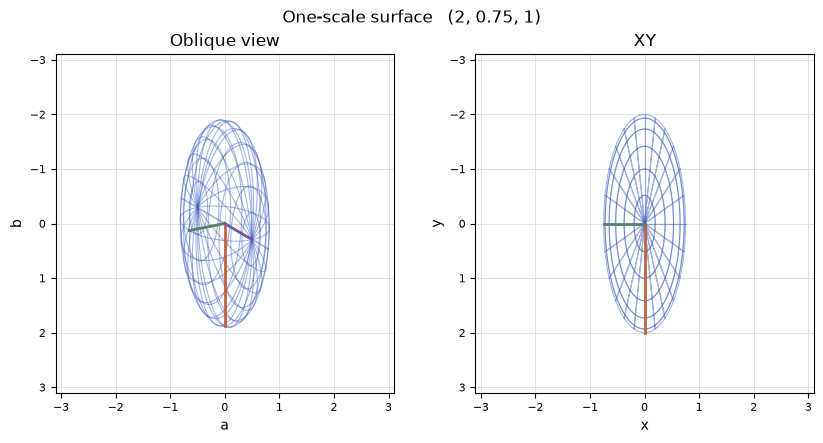

In [6]:
fig = demos.ellipsoid_figure("en", angle=90)
plt.show()

In [7]:
q45 = geo.axis_angle_quaternion([0,0,1], 45)
cov = geo.covariance_3d(scales, q45)
print("Σ =\n", cov)
delta = geo.quaternion_matrix(q45) @ (scales*h)
relative_squared = delta @ np.linalg.solve(cov, delta)
print("G on shell =", np.exp(-relative_squared/2))
np.testing.assert_allclose(relative_squared, 1)

Σ =
 [[2.2812 1.7188 0.    ]
 [1.7188 2.2813 0.    ]
 [0.     0.     1.    ]]
G on shell = 0.6065306597126333


## 5. Where the geometry breaks

**An experiment.** An ellipsoid has scales $(2,1,1)$. First it turns about the long $x$ axis. In a separate experiment it turns about $z$. Which turn changes the silhouette viewed along $z$?

<details>
<summary>Working it out</summary>

For the first turn the two transverse sizes agree. Rotating their circle leaves the surface intact. The matrix remains $\mathrm{diag}(4,1,1)$. A $90^\circ$ turn about $z$ carries the long direction into $y$ and gives $\mathrm{diag}(1,4,1)$. The horizontal ellipse becomes vertical.

</details>

**A flat cloud.** What happens if $s_z=0$?

<details>
<summary>Working it out</summary>

The third displacement would have to be divided by zero. The shape matrix acquires a zero-width direction and can no longer recover the displacement along it. A flat disk has a geometry of its own, but a volumetric Gaussian weight needs three nonzero scales. Hence the experiment keeps the lower bound positive.

</details>

The same axis and half-angle representation appears in [SciPy's quaternion reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.from_quat.html). The location of the scalar component matters when exchanging rotation data.